In [1]:
%load_ext autoreload
%autoreload 2
from CrocoDash.grid import Grid
from CrocoDash.topo import Topo
from CrocoDash.vgrid import VGrid
from pathlib import Path
from CrocoDash.case import Case

In [4]:
# CESM case (experiment) name
casename = "cli.test.1"

# CESM source root (Update this path accordingly!!!)
cesmroot ="/glade/u/home/manishrv/work/installs/CROCESM_workshop_2025"

# Place where all your input files go 
inputdir = Path.home()/"scratch" / "croc_input" / casename
    
# CESM case directory
caseroot = Path.home() / "croc_cases" / casename

grid_path = "/glade/derecho/scratch/manishrv/croc_input/bd.oo.10thdegree/ocnice/ocean_hgrid_open_ocean_nar_10_4ea79c.nc"
bathymetry_path = "/glade/derecho/scratch/manishrv/croc_input/bd.oo.10thdegree/ocnice/ocean_topog_open_ocean_nar_10_4ea79c.nc"
compset = "1850_DATM%NYF_SLND_SICE_MOM6_SROF_SGLC_SWAV"

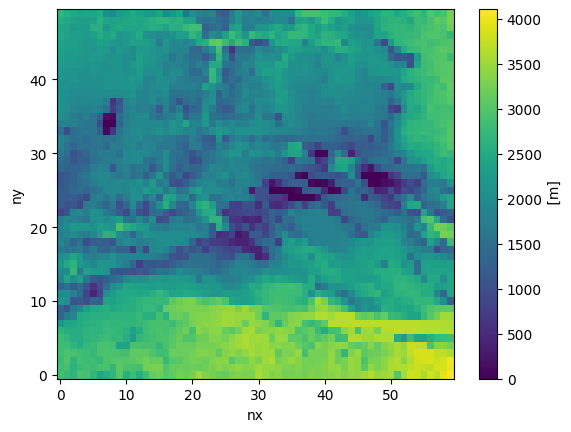

In [5]:
grid = Grid.from_supergrid(grid_path)
topo = Topo.from_topo_file(
    grid = grid,
    topo_file_path=bathymetry_path,
    min_depth = 9.5,
)
topo.depth.plot()
vgrid  = VGrid.hyperbolic(
    nk = 75,
    depth = topo.max_depth,
    ratio=20.0
)

In [ ]:

case = Case(
    cesmroot = cesmroot,
    caseroot = caseroot,
    inputdir = inputdir,
    ocn_grid = grid,
    ocn_vgrid = vgrid,
    ocn_topo = topo,
    project = 'NCGD0011',
    override = True,
    machine = "derecho",
    compset = compset,
    atm_grid_name = "T62"
)

INFO:	initialize:Initializing the visualCaseGen system...


In [ ]:
case.configure_forcings(
    date_range = ["2000-01-01 00:00:00", "2000-01-03 00:00:00"],
    function_name="get_glorys_data_from_rda",
)
#case.process_forcings()


INFO:CrocoDash.forcing_configurations.base:[SKIP] tides missing args: ['tpxo_elevation_filepath', 'tpxo_velocity_filepath', 'tidal_constituents']
INFO:CrocoDash.forcing_configurations.base:[REQUIRED] Activating BGC
INFO:CrocoDash.forcing_configurations.base:[SKIP] CICE incompatible with compset
INFO:CrocoDash.forcing_configurations.base:[REQUIRED] Activating BGCIC
INFO:CrocoDash.forcing_configurations.base:[REQUIRED] Activating BGCIronForcing
INFO:CrocoDash.forcing_configurations.base:[SKIP] BGCRiverNutrients incompatible with compset
INFO:CrocoDash.forcing_configurations.base:[SKIP] Runoff incompatible with compset
INFO:CrocoDash.forcing_configurations.base:[SKIP] Chl incompatible with compset
INFO:CrocoDash.forcing_configurations.base:Configuring BGC
INFO:CrocoDash.forcing_configurations.base:Configuring BGCIC
INFO:CrocoDash.forcing_configurations.base:Configuring BGCIronForcing


Adding parameter changes to user_nl_mom:

  ! Maximum number of tracer fields, bumped to accomodate MARBL tracers
  MAX_FIELDS = 200

Adding parameter changes to user_nl_mom:

  ! MARBL initial conditions file
  MARBL_TRACERS_IC_FILE = ecosys_jan_IC_omip_latlon_1x1_180W_c231221.nc

Adding parameter changes to user_nl_mom:

  ! MARBL sedimentary iron flux file
  MARBL_FESEDFLUX_FILE = fesedflux_total_reduce_oxic_panama1_0cf606.nc

Adding parameter changes to user_nl_mom:

  ! MARBL event iron flux file
  MARBL_FEVENTFLUX_FILE = feventflux_5gmol_panama1_0cf606.nc

Adding parameter changes to user_nl_mom:

  ! Initial conditions
  INIT_LAYERS_FROM_Z_FILE = True
  Z_INIT_ALE_REMAPPING = True
  TEMP_SALT_INIT_VERTICAL_REMAP_ONLY = True
  DEPRESS_INITIAL_SURFACE = True
  VELOCITY_CONFIG = file
  TEMP_SALT_Z_INIT_FILE = init_tracers.nc
  SURFACE_HEIGHT_IC_FILE = init_eta.nc
  VELOCITY_FILE = init_vel.nc
  Z_INIT_FILE_PTEMP_VAR = temp
  Z_INIT_FILE_SALT_VAR = salt
  SURFACE_HEIGHT_IC_VAR = eta

In [ ]:
# SAVED WAY
import shutil
# Copy the shutil forcings
old_forcing_dir = Path("/glade/derecho/scratch/manishrv/croc_input/pan.bgc.1/ocnice/")
# Copy all files starting with 'forcing_'
for file in old_forcing_dir.glob("*_obc_*"):
    if file.is_file():
        shutil.copy(file, case.inputdir/"ocnice" / file.name)
for file in old_forcing_dir.glob("*_IC*"):
    if file.is_file():
        shutil.copy(file, case.inputdir/"ocnice" / file.name)

In [8]:
case.inputdir

PosixPath('/glade/u/home/manishrv/scratch/croc_input/vcg.xml.4')